# Forecasting Pacific Northwest Electricity Demand

**Goal:** 
Using the weather and calendar, forecast the hourly electricity demand for the Bonneville Power Administration (BPA) a day ahead with an honest range for each forecast. We use EIA's own published day-ahead forecast is the benchmark.

This notebook is the summary for the forecast. This means it loads saved results and re-fits nothing and the working notebooks (00–06) show the decisions made and what didn't work.

**The Headline for the test period of Jan 2025 – Aug 2026 (scored once, bold is our best model):**

| forecast | MAPE | bias (MWh) | 90% interval coverage |
|---|---|---|---|
| EIA day-ahead (benchmark) | 1.94% | +7 | n/a |
| Gradient boosting + trend | 4.86% | −338 | n/a |
| Bayesian regression | 4.93% | −322 | 59.6% |
| **Bayesian regression + recent-error correction** | **2.68%** | **−8** | **89.6%** |

1. The weather and the calendar explain demand well. 
    - On 2024 the Bayesian model was within 2.7% and its 90% intervals held 92% of the time.
2. During the test period, demand moved up to a new level twice. The weather can't see that, so every weather-only model fell about 320–340 MWh short and the intervals stopped holding.
3. Correcting each day by the model's recent errors, using only data available a day ahead, cuts the error almost in half and brings coverage back to 90%. 
    - EIA is still better.

In [1]:
import sys; sys.path.append("..")

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import arviz as az
from pathlib import Path

from src.bayes_model import load_features, build_X, slot_index, predictive_draws, DEMAND_SCALE, ALL_WEATHER
from src.recent_correction import scores, point_scores, daily_errors, window_offsets, bayes_offsets, apply_offsets

SEED = 1145
RESULTS = Path("../results")
PACIFIC = "America/Los_Angeles"
WINDOW = 14  #correction window, chosen on 2024 in notebook 06

con = duckdb.connect("../data/grid.duckdb", read_only=True)
con.sql("SET TimeZone = 'UTC'")

df = load_features(con)
train, valid, test = (df[df["split"] == s].reset_index(drop=True) for s in ["train", "valid", "test"])
print(f"hours -> train (2021–2023): {len(train):,}  valid (2024): {len(valid):,}  test (Jan 2025 – Aug 2026): {len(test):,}")

#saved posterior samples from notebook 05
idata_valid = az.from_netcdf(RESULTS / "idata_m4_full.nc") #fit on 2021–2023, scored on 2024
idata_test = az.from_netcdf(RESULTS / "idata_m4_final.nc") #refit on 2021–2024, scored on the test period
idata_m5e = az.from_netcdf(RESULTS / "idata_m5e_sub.nc")  #size of month-to-month surprises (prior for the correction)

#notebook 04 saved test predictions (EIA, GBM, baselines)
preds = con.sql("SELECT * FROM predictions_test ORDER BY period_utc").df()
assert (preds["period_utc"].values == test["period_utc"].values).all()
has_eia = preds["eia_forecast_mwh"].notna().values  #all test scores use the hours EIA has a forecast for

hours -> train (2021–2023): 26,240  valid (2024): 8,784  test (Jan 2025 – Aug 2026): 14,584


## 1. Data

- **Demand and EIA's day-ahead forecast:** [EIA-930 Hourly Grid Monitor](https://www.eia.gov/opendata/browser/electricity/rto/region-data), balancing authority `BPAT`, 2021 to Aug 2026.
- **Weather:** [Open-Meteo](https://open-meteo.com/en/docs/historical-weather-api) hourly reanalysis for BPA load centers (Everett, Kennewick, Vancouver WA, Eugene).
- **Split by time:** train on 2021–2023, choose settings on 2024, and score the test period (Jan 2025 – Aug 2026) once at the end. 

## 2. What drives demand

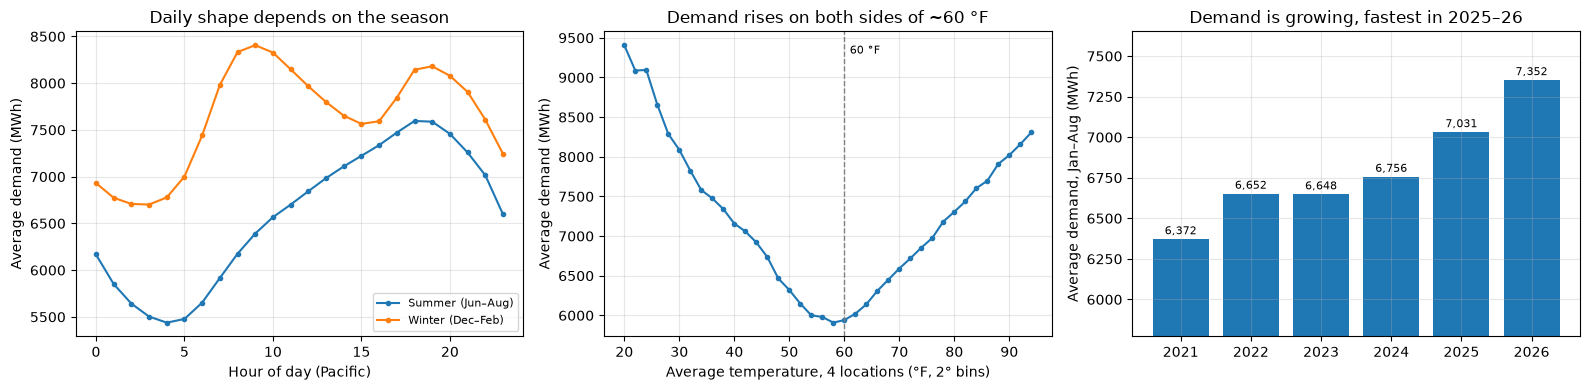

In [ ]:
eda = con.sql(f'''
    SELECT period_utc, demand_mwh, month, hour_pacific,
           (eugene_temp_f + everett_temp_f + kennewick_temp_f + vancouver_wash_temp_f) / 4 AS temp_avg_f
    FROM features_hourly WHERE demand_mwh IS NOT NULL
''').df()

local = eda["period_utc"].dt.tz_convert(PACIFIC)
eda["year"] = local.dt.year

eda = eda[eda["year"] >= 2021]  #the first 8 UTC hours are still Dec 31 2020 in Pacific time

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

#daily shape: winter vs summer
season = eda["month"].map({12: "Winter (Dec–Feb)", 1: "Winter (Dec–Feb)", 2: "Winter (Dec–Feb)",
                           6: "Summer (Jun–Aug)", 7: "Summer (Jun–Aug)", 8: "Summer (Jun–Aug)"})
shape = eda.groupby([season, "hour_pacific"])["demand_mwh"].mean().unstack(0)
for col in shape.columns:
    axes[0].plot(shape.index, shape[col], marker="o", markersize=3, label=col)
axes[0].set_xlabel("Hour of day (Pacific)")
axes[0].set_ylabel("Average demand (MWh)")
axes[0].set_title("Daily shape depends on the season")
axes[0].legend(fontsize=8)

#temperature response: a V with the bottom near 60 F
bins = (eda["temp_avg_f"] // 2) * 2
v = eda.groupby(bins)["demand_mwh"].agg(["mean", "size"])
v = v[v["size"] >= 50]

axes[1].plot(v.index, v["mean"], marker="o", markersize=3)
axes[1].axvline(60, color="gray", linestyle="--", linewidth=1)
axes[1].text(61, v["mean"].max(), "60 °F", va="top", fontsize=8)
axes[1].set_xlabel("Average temperature, 4 locations (°F, 2° bins)")
axes[1].set_ylabel("Average demand (MWh)")
axes[1].set_title("Demand rises on both sides of ~60 °F")

#growth: Jan–Aug average by year (2026 only has Jan–Aug)
jan_aug = eda[local.loc[eda.index].dt.month <= 8].groupby("year")["demand_mwh"].mean()

axes[2].bar(jan_aug.index.astype(str), jan_aug.values)
for x, y in zip(jan_aug.index.astype(str), jan_aug.values):
    axes[2].text(x, y + 30, f"{y:,.0f}", ha="center", fontsize=8)

axes[2].set_ylim(jan_aug.min() - 600, jan_aug.max() + 300)
axes[2].set_ylabel("Average demand, Jan–Aug (MWh)")
axes[2].set_title("Demand is growing, fastest in 2025–26")

for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- **Daily shape changes with the season.** Winter has a morning and an evening peak, from heating while Summer builds to one late-afternoon peak. So the model gets a separate level for each season × hour (96 "slots").
- **Temperature response is a V.** Demand is lowest around 58–60 °F and rises with heating below that and cooling above it. Plain temperature correlates weakly with demand because the two sides cancel out. Splitting it into **heating and cooling degree-hours** (how far below or above 60 °F) turns each side into a straight line. A 12-hour rolling version helps too, because buildings respond to the last half day of weather, not only the current hour.
- **Demand is growing.** The Jan–Aug average rose about 15% from 2021 to 2026, with the biggest jumps in 2025 and 2026. That growth is what the rest of the story is about.

## 3. The model

A Bayesian linear regression in PyMC (model `m4` in notebook 05):

```
demand ~ Normal(mu, sigma[slot])
mu     = level[slot]                      96 season × hour slots
       + weekend + major holiday
       + trend × years since start        straight-line growth
       + heating and cooling degree-hours    current and 12h rolling, for Everett, Kennewick, Vancouver WA
```

- **Why Bayesian:** it gives a range of number per hour and every effect comes with its uncertainty. The question that matters is whether the 90% ranges contain the actual demand 90% of the time.
- **Priors from domain knowledge (the EDA), not the data:** each slot level is centered on 7,000 MWh (± 2,000); weekend, holiday, trend and weather weights are Normal(0, 500 MWh).
- **Noise varies by slot.** Winter ramps are much harder to predict than spring nights. With a single noise level, the ranges were too narrow in winter and too wide in spring, so each slot gets its own `sigma`, partly pooled toward a shared typical value.

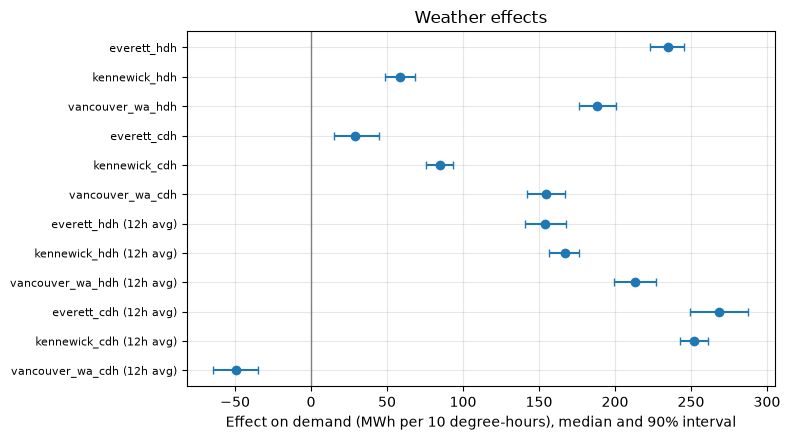

trend: 116 MWh per year (90% interval 114 to 118)


In [ ]:
#weather effects with uncertainty (MWh per 10 degree-hours), from the model refit on 2021–2024
beta = idata_test.posterior["beta"].sel(feature=ALL_WEATHER) * DEMAND_SCALE
med = beta.median(dim=("chain", "draw")).to_series()
lo = beta.quantile(0.05, dim=("chain", "draw")).to_series()
hi = beta.quantile(0.95, dim=("chain", "draw")).to_series()

order = med.index[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))

ax.errorbar(med[order], range(len(order)), xerr=[med[order] - lo[order], hi[order] - med[order]], fmt="o", capsize=3)

ax.axvline(0, color="gray", linewidth=1)

ax.set_yticks(range(len(order)))
ax.set_yticklabels([c.replace("vancouver_wash", "vancouver_wa").replace("12", " (12h avg)") for c in order], fontsize=8)
ax.set_xlabel("Effect on demand (MWh per 10 degree-hours) with median and 90% interval")
ax.set_title("Weather effects")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

trend = idata_test.posterior["beta"].sel(feature="years_since_start") * DEMAND_SCALE
print(f"trend: {float(trend.median()):.0f} MWh per year (90% interval {float(trend.quantile(0.05)):.0f} to {float(trend.quantile(0.95)):.0f})")

- **Every heating and cooling effect is clearly away from zero**, and the 90% intervals are narrow because 35,000 hours pin them down. For each location, the current-hour and 12-hour versions add together. For example, 10 more heating degree-hours at Everett, both now and over the last 12 hours, adds about 390 MWh.
- **One effect is negative: Vancouver WA's 12-hour cooling.** The current and 12-hour versions of the same temperature carry overlapping information, so the model can split credit between them. Vancouver's two cooling effects together still come to about +105 MWh per 10 degree-hours.
- **Trend: about 116 MWh per year**, a straight line fit on 2021–2024. Section 5 shows why that isn't enough.

## 4. Choosing settings on 2024: the model is calibrated

The model fit on 2021–2023 is scored on 2024, the validation year.

In [ ]:
y_va = predictive_draws(idata_valid, build_X(valid), slot_index(valid), seed=SEED)

a_va = valid["demand_mwh"].values
eia_va = valid["eia_forecast_mwh"].notna().values

pd.concat([
    point_scores(valid["eia_forecast_mwh"].values, a_va, "EIA day-ahead (benchmark)", eia_va),
    scores(y_va, a_va, "Bayesian m4", eia_va),
], ignore_index=True)

,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh,coverage_pct,width_mwh
0,EIA day-ahead (benchmark),134.68,1.97,178.53,-18.27,NaN,NaN
1,Bayesian m4,184.28,2.73,235.26,-67.21,91.91,799.76


- **The 90% intervals held 91.9% of 2024's hours**, and in notebook 05 every hour of the day was within about 89–94%.
- **Accuracy: 2.73% MAPE vs EIA's 1.97%.** Notebook 04's gradient boosting got 2.14% on 2024, but it gives one number per hour with no range.
- **It already ran about 67 MWh low in 2024.** That was the first sign the straight-line trend was falling behind.

## 5. Test period: demand moved to a new level

The model refit on 2021–2024 forecasts Jan 2025 – Aug 2026.

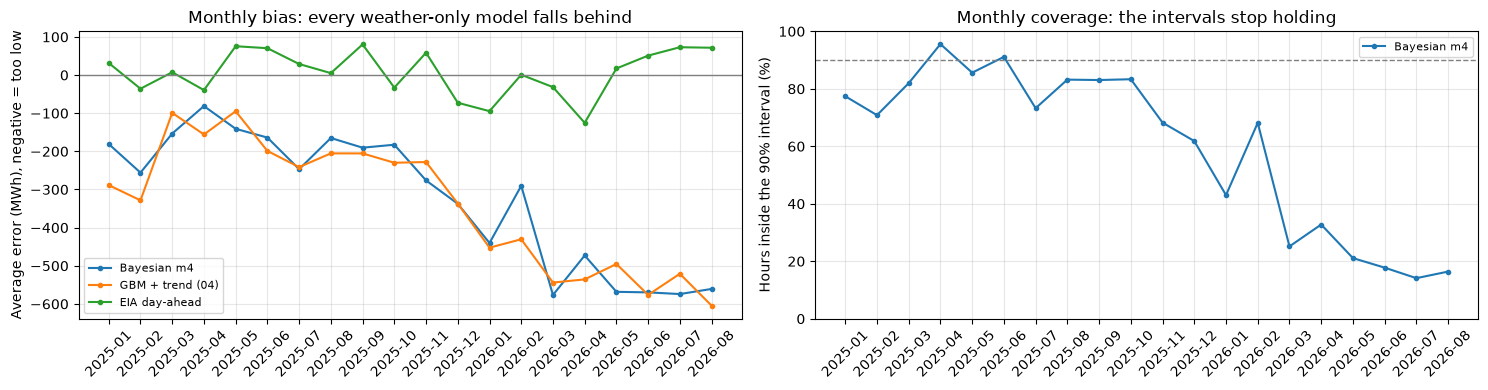

In [ ]:
y_te = predictive_draws(idata_test, build_X(test), slot_index(test), seed=SEED)
a_te = test["demand_mwh"].values
months_te = test["period_utc"].dt.tz_convert(PACIFIC).dt.strftime("%Y-%m").values

def by_month(y_draws):
    '''Monthly bias (forecast - actual) and 90% interval coverage, on hours with an EIA forecast'''
    lo, hi = np.percentile(y_draws, 5, axis=0), np.percentile(y_draws, 95, axis=0)
    med = np.median(y_draws, axis=0)
    m = months_te[has_eia]
    bias = pd.Series(med - a_te)[has_eia].groupby(m).mean()
    cov = pd.Series((a_te >= lo) & (a_te <= hi))[has_eia].groupby(m).mean() * 100
    return bias, cov

def bias_of(pred):
    return pd.Series(pred - a_te)[has_eia].groupby(months_te[has_eia]).mean()

bias_m4, cov_m4 = by_month(y_te)
bias_eia = bias_of(preds["eia_forecast_mwh"].values)
bias_gbm = bias_of(preds["pred_gbm"].values)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(bias_m4.index, bias_m4, marker="o", markersize=3, label="Bayesian m4")
axes[0].plot(bias_gbm.index, bias_gbm, marker="o", markersize=3, label="GBM + trend (04)")
axes[0].plot(bias_eia.index, bias_eia, marker="o", markersize=3, label="EIA day-ahead")
axes[0].axhline(0, color="gray", linewidth=1)
axes[0].set_ylabel("Average error (MWh), negative = too low")
axes[0].set_title("Monthly bias: every weather-only model falls behind")

axes[1].plot(cov_m4.index, cov_m4, marker="o", markersize=3, label="Bayesian m4")
axes[1].axhline(90, color="gray", linestyle="--", linewidth=1)
axes[1].set_ylim(0, 100)
axes[1].set_ylabel("Hours inside the 90% interval (%)")
axes[1].set_title("Monthly coverage: the intervals stop holding")

for ax in axes:
    ax.tick_params(axis="x", labelrotation=45)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
    
plt.tight_layout()
plt.show()

- **Demand stepped up twice:** the Bayesian model and the GBM both run about 80–280 MWh low through most of 2025, then about 290–580 MWh low from December 2025 on. EIA stays within about ±125 MWh the whole time. The two weather-only models fail in the same way because they share the same blind spot which is nothing in weather or the calendar says the level moved.
- **The intervals collapse:** 59.6% coverage overall and 14–33% from March 2026, with almost every miss on the same side (actual demand above the range). The width never reacts, so the model is as confident 20 months out as it was one month out.
- **What kind of load:** the shortfall is about the same in MWh at every hour of the day, which points to new load that runs around the clock rather than extra heating or cooling. The data can't confirm the cause.

## 6. The fix: correct each day with recent demand

Weather can't see a new block of load, but the model's own recent errors can. Each day:

1. Take the model's average error for each recent day (one number per day, because hours within a day move together).
2. **Use only days up to D−2.** The forecast for day D is made during D−1, so D−2 is the last complete day. This keeps the correction something that could actually run each morning.
3. Shift every hour of day D by the average of the last **14** of those daily errors.

The 14-day window was chosen on 2024 (lowest MAPE with coverage between 88% and 94%). Shorter windows chase the last cold snap, and longer ones are slow to follow a shift.

A **Bayesian version** of the correction was also tested. It treats the offset as uncertain, starts from a prior that offsets are usually small (about ±120 MWh, the size of month-to-month surprises in 2021–2023), updates on the same recent days, and widens the interval by how unsure it is. It was slightly better on 2024.

In [6]:
#settings for the Bayesian version come from the training years only
prior_sd = float(idata_m5e.posterior["shock_sd"].mean()) * DEMAND_SCALE
y_tr = predictive_draws(idata_valid, build_X(train), slot_index(train), seed=SEED)
day_sd = daily_errors(y_tr, train)[0].std()
print(f"prior_sd {prior_sd:.0f} MWh, day_sd {day_sd:.0f} MWh")

daily_te, dates_te = daily_errors(y_te, test)
y_te_avg = apply_offsets(y_te, dates_te, window_offsets(daily_te, WINDOW))
y_te_bayes = apply_offsets(y_te, dates_te, *bayes_offsets(daily_te, WINDOW, prior_sd, day_sd))

pd.concat([
    point_scores(preds["eia_forecast_mwh"].values, a_te, "EIA day-ahead (benchmark)", has_eia),
    scores(y_te_avg, a_te, f"m4 + average error, last {WINDOW} days", has_eia),
    scores(y_te_bayes, a_te, f"m4 + Bayesian update, last {WINDOW} days", has_eia),
    point_scores(preds["pred_gbm"].values, a_te, "GBM + weather-adjusted trend (04)", has_eia),
    scores(y_te, a_te, "Bayesian m4, no correction", has_eia),
    point_scores(preds["pred_linear"].values, a_te, "Linear regression (04)", has_eia),
    point_scores(preds["pred_last_week"].values, a_te, "Same hour last week", has_eia),
], ignore_index=True)

prior_sd 121 MWh, day_sd 175 MWh


,model,mae_mwh,mape_pct,rmse_mwh,bias_mwh,coverage_pct,width_mwh
0,EIA day-ahead (benchmark),138.37,1.94,181.58,6.97,NaN,NaN
1,"m4 + average error, last 14 days",189.87,2.68,244.13,-7.57,89.62,781.28
2,"m4 + Bayesian update, last 14 days",192.52,2.71,247.61,-48.79,89.77,795.00
3,GBM + weather-adjusted trend (04),349.40,4.86,414.12,-337.86,NaN,NaN
4,"Bayesian m4, no correction",354.26,4.93,432.47,-321.62,59.64,781.28
5,Linear regression (04),384.73,5.34,467.28,-346.43,NaN,NaN
6,Same hour last week,424.68,5.83,576.35,2.84,NaN,NaN


| on the same 14,560 test hours | MAPE | bias (MWh) | 90% coverage |
|---|---|---|---|
| EIA day-ahead | **1.94%** | +7 | n/a |
| **m4 + average error, last 14 days** | **2.68%** | **−8** | **89.6%** |
| m4 + Bayesian update, last 14 days | 2.71% | −49 | 89.8% |
| GBM + weather-adjusted trend (04) | 4.86% | −338 | n/a |
| Bayesian m4, no correction | 4.93% | −322 | 59.6% |

- **The error almost halves (4.93% → 2.68%)**, the bias drops from −322 to −8 MWh, and coverage returns to about 90%.
- **The simple average beats the Bayesian update here**, though the Bayesian update was slightly better on 2024. Its prior expects offsets of about ±120 MWh, but by 2026 the real offset was about 570 MWh, nearly 5× that. Each day the prior pulls part of the correction back toward zero, so it stays too low (a prior–data conflict).
- **EIA is still better.** It also sees recent demand, uses forecasting models built for this, and probably has more recent data than the D−2 rule allows.

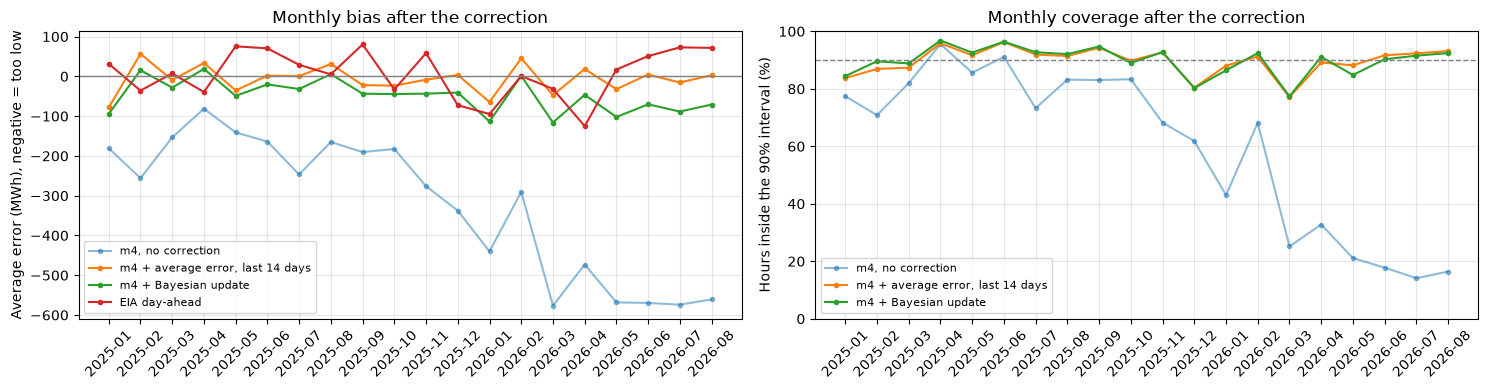

In [7]:
bias_avg, cov_avg = by_month(y_te_avg)
bias_bayes, cov_bayes = by_month(y_te_bayes)

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
axes[0].plot(bias_m4.index, bias_m4, marker="o", markersize=3, label="m4, no correction", alpha=0.5)
axes[0].plot(bias_avg.index, bias_avg, marker="o", markersize=3, label=f"m4 + average error, last {WINDOW} days")
axes[0].plot(bias_bayes.index, bias_bayes, marker="o", markersize=3, label="m4 + Bayesian update")
axes[0].plot(bias_eia.index, bias_eia, marker="o", markersize=3, label="EIA day-ahead")
axes[0].axhline(0, color="gray", linewidth=1)
axes[0].set_ylabel("Average error (MWh), negative = too low")
axes[0].set_title("Monthly bias after the correction")

axes[1].plot(cov_m4.index, cov_m4, marker="o", markersize=3, label="m4, no correction", alpha=0.5)
axes[1].plot(cov_avg.index, cov_avg, marker="o", markersize=3, label=f"m4 + average error, last {WINDOW} days")
axes[1].plot(cov_bayes.index, cov_bayes, marker="o", markersize=3, label="m4 + Bayesian update")
axes[1].axhline(90, color="gray", linestyle="--", linewidth=1)
axes[1].set_ylim(0, 100)
axes[1].set_ylabel("Hours inside the 90% interval (%)")
axes[1].set_title("Monthly coverage after the correction")

for ax in axes:
    ax.tick_params(axis="x", labelrotation=45)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

- **Bias:** the 14-day average correction stays between about −80 and +60 MWh every month, about as close to zero as EIA. The Bayesian update stays below it every month, by up to about 75 MWh in 2026, which is the prior–data conflict month by month.
- **Coverage:** both corrections hold 77–97% every month, instead of falling to 14–33%. Their coverage is almost identical, so the Bayesian version's slightly wider ranges barely changed it.

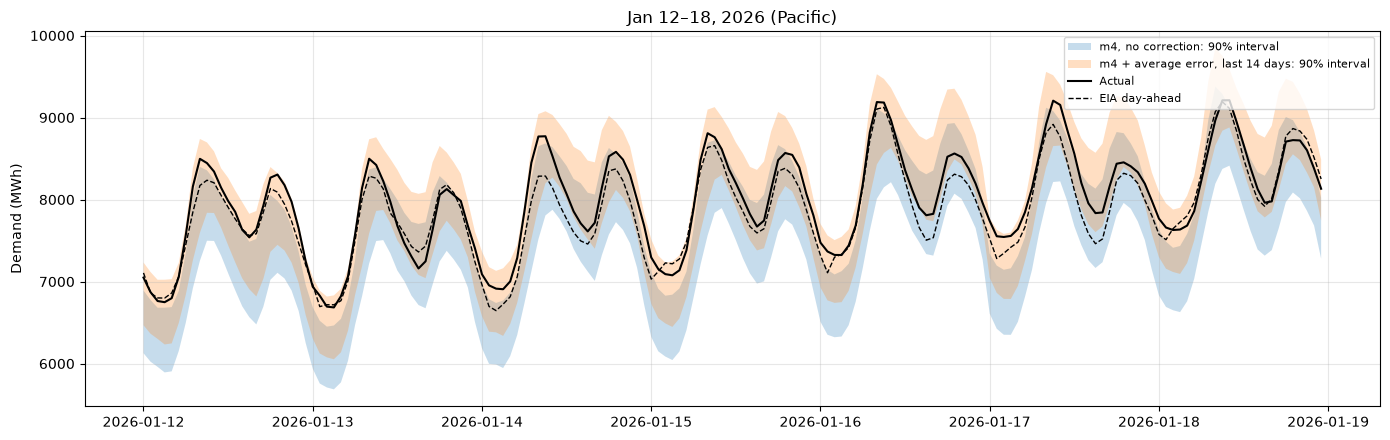

In [8]:
#one winter week, hour by hour
week = ((test["period_utc"] >= "2026-01-12 08:00:00+00") & (test["period_utc"] < "2026-01-19 08:00:00+00")).values
t = test.loc[week, "period_utc"].dt.tz_convert(PACIFIC)

fig, ax = plt.subplots(figsize=(14, 4.5))
for draws, label in [(y_te, "m4, no correction"), (y_te_avg, f"m4 + average error, last {WINDOW} days")]:
    lo, hi = np.percentile(draws[:, week], 5, axis=0), np.percentile(draws[:, week], 95, axis=0)
    ax.fill_between(t, lo, hi, alpha=0.25, label=f"{label}: 90% interval")
ax.plot(t, test.loc[week, "demand_mwh"], color="black", linewidth=1.5, label="Actual")
ax.plot(t, test.loc[week, "eia_forecast_mwh"], color="black", linestyle="--", linewidth=1, label="EIA day-ahead")
ax.set_ylabel("Demand (MWh)")
ax.set_title("Jan 12–18, 2026 (Pacific)")
ax.legend(fontsize=8, loc="upper right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In a cold week in January 2026, the uncorrected forecast (blue) sits mostly below actual demand, and the actual line runs along or above the top of its range. The corrected forecast (orange) is the same shape moved up by the recent offset, and actual demand stays inside its range. EIA follows actual demand more closely still.

## 7. Takeaways

- **Weather and the calendar explain demand well, until the level moves.** On 2024 the Bayesian model was within 2.7% and its intervals were calibrated. In 2025–26, two step-ups in demand pushed every weather-only model about 320–340 MWh too low, and the intervals held only 60% of hours.
- **The calibration check is what showed this.** A point forecast that is 5% off looks only somewhat worse. An interval that says 90% and delivers 15% shows the level, not the weather response or the noise, broke
- **Recent demand fixes most of it.** A 14-day average of the model's own recent errors, using only data available a day ahead, cuts the test error from 4.93% to 2.68% and brings coverage back to about 90%.
- **The prior has to fit the situation.** The Bayesian correction was slightly better on 2024, when offsets were small, and worse on 2025–26, when the offset was about 5× larger than its prior expected. A prior that can grow is the natural next step.

**Limitations**
- The D−2 rule is conservative. EIA probably uses more recent data.
- The correction is one offset for the whole day. That suits the 2025–26 shifts, which looked like a constant block of extra load at every hour.
- Hour-to-hour errors are strongly correlated, so ranges for a whole day or a peak would be too narrow even where hourly coverage is right.

**Next**
- Score with forecast weather.
- Give the correction a prior that can grow when offsets are large.

In [9]:
con.close()